In [1]:
import pandas as pd
import numpy as np
import re

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [2]:
df = pd.read_csv("nlp_dataset.csv")

df.head()

,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nEmotion Distribution:")

Dataset Shape: (5937, 2)

Column Names:
Index(['Comment', 'Emotion'], dtype='object')

Missing Values:
Comment    0
Emotion    0
dtype: int64

Duplicate Rows:
0

Emotion Distribution:


In [4]:
# Convert text into lowercase

df['Cleaned_Comment'] = df['Comment'].str.lower()

df[['Comment', 'Cleaned_Comment']].head()

,Comment,Cleaned_Comment
0,i seriously hate one subject to death but now ...,i seriously hate one subject to death but now ...
1,im so full of life i feel appalled,im so full of life i feel appalled
2,i sit here to write i start to dig out my feel...,i sit here to write i start to dig out my feel...
3,ive been really angry with r and i feel like a...,ive been really angry with r and i feel like a...
4,i feel suspicious if there is no one outside l...,i feel suspicious if there is no one outside l...


In [5]:
df['Cleaned_Comment'] = df['Cleaned_Comment'].apply(
    lambda x: re.sub(r'[^a-z\s]', '', x)
)

df[['Comment', 'Cleaned_Comment']].head()

,Comment,Cleaned_Comment
0,i seriously hate one subject to death but now ...,i seriously hate one subject to death but now ...
1,im so full of life i feel appalled,im so full of life i feel appalled
2,i sit here to write i start to dig out my feel...,i sit here to write i start to dig out my feel...
3,ive been really angry with r and i feel like a...,ive been really angry with r and i feel like a...
4,i feel suspicious if there is no one outside l...,i feel suspicious if there is no one outside l...


In [6]:
nltk.download('punkt_tab')

df['Tokens'] = df['Cleaned_Comment'].apply(word_tokenize)

df[['Cleaned_Comment', 'Tokens']].head()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Ancy\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


,Cleaned_Comment,Tokens
0,i seriously hate one subject to death but now ...,"[i, seriously, hate, one, subject, to, death, ..."
1,im so full of life i feel appalled,"[im, so, full, of, life, i, feel, appalled]"
2,i sit here to write i start to dig out my feel...,"[i, sit, here, to, write, i, start, to, dig, o..."
3,ive been really angry with r and i feel like a...,"[ive, been, really, angry, with, r, and, i, fe..."
4,i feel suspicious if there is no one outside l...,"[i, feel, suspicious, if, there, is, no, one, ..."


In [7]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

df['Filtered_Tokens'] = df['Tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

df[['Tokens', 'Filtered_Tokens']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ancy\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


,Tokens,Filtered_Tokens
0,"[i, seriously, hate, one, subject, to, death, ...","[seriously, hate, one, subject, death, feel, r..."
1,"[im, so, full, of, life, i, feel, appalled]","[im, full, life, feel, appalled]"
2,"[i, sit, here, to, write, i, start, to, dig, o...","[sit, write, start, dig, feelings, think, afra..."
3,"[ive, been, really, angry, with, r, and, i, fe...","[ive, really, angry, r, feel, like, idiot, tru..."
4,"[i, feel, suspicious, if, there, is, no, one, ...","[feel, suspicious, one, outside, like, rapture..."


In [8]:
stop_words = set(stopwords.words('english'))

# Keep important negative words
stop_words = stop_words - {'not', 'no', 'nor', 'never'}

df['Filtered_Tokens'] = df['Tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

In [9]:
df[['Tokens', 'Filtered_Tokens']].head()

,Tokens,Filtered_Tokens
0,"[i, seriously, hate, one, subject, to, death, ...","[seriously, hate, one, subject, death, feel, r..."
1,"[im, so, full, of, life, i, feel, appalled]","[im, full, life, feel, appalled]"
2,"[i, sit, here, to, write, i, start, to, dig, o...","[sit, write, start, dig, feelings, think, afra..."
3,"[ive, been, really, angry, with, r, and, i, fe...","[ive, really, angry, r, feel, like, idiot, tru..."
4,"[i, feel, suspicious, if, there, is, no, one, ...","[feel, suspicious, no, one, outside, like, rap..."


In [10]:
df['Final_Text'] = df['Filtered_Tokens'].apply(
    lambda words: ' '.join(words)
)

df[['Filtered_Tokens', 'Final_Text']].head()

,Filtered_Tokens,Final_Text
0,"[seriously, hate, one, subject, death, feel, r...",seriously hate one subject death feel reluctan...
1,"[im, full, life, feel, appalled]",im full life feel appalled
2,"[sit, write, start, dig, feelings, think, afra...",sit write start dig feelings think afraid acce...
3,"[ive, really, angry, r, feel, like, idiot, tru...",ive really angry r feel like idiot trusting fi...
4,"[feel, suspicious, no, one, outside, like, rap...",feel suspicious no one outside like rapture ha...


In [11]:
tfidf = TfidfVectorizer()

X = tfidf.fit_transform(df['Final_Text'])

y = df['Emotion']

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (5937, 8818)
Target Shape: (5937,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4749, 8818)
X_test: (1188, 8818)
y_train: (4749,)
y_test: (1188,)


In [13]:
# Import Naive Bayes

from sklearn.naive_bayes import MultinomialNB

# Create model
nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [14]:
# Calculate Accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

# Classification Report
print("Naive Bayes Accuracy:", nb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.8905723905723906

Classification Report:
              precision    recall  f1-score   support

       anger       0.88      0.91      0.89       400
        fear       0.87      0.91      0.89       388
         joy       0.93      0.86      0.89       400

    accuracy                           0.89      1188
   macro avg       0.89      0.89      0.89      1188
weighted avg       0.89      0.89      0.89      1188



In [15]:
# Import SVM
from sklearn.svm import LinearSVC

# Create model
svm_model = LinearSVC()

# Train model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [16]:
# Calculate Accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Classification Report
print("SVM Accuracy:", svm_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9377104377104377

Classification Report:
              precision    recall  f1-score   support

       anger       0.94      0.93      0.94       400
        fear       0.94      0.93      0.94       388
         joy       0.93      0.95      0.94       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



In [17]:
comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM'],
    'Accuracy': [nb_accuracy, svm_accuracy]
})

comparison['Accuracy'] = comparison['Accuracy'] * 100

print(comparison)

         Model   Accuracy
0  Naive Bayes  89.057239
1          SVM  93.771044


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

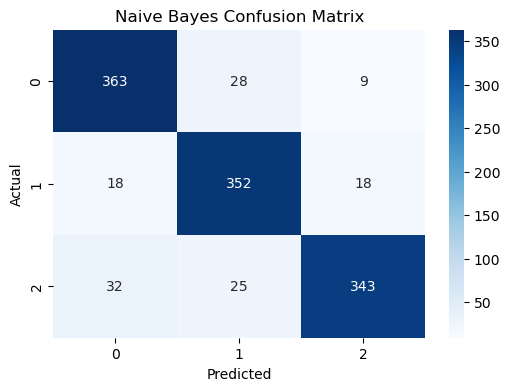

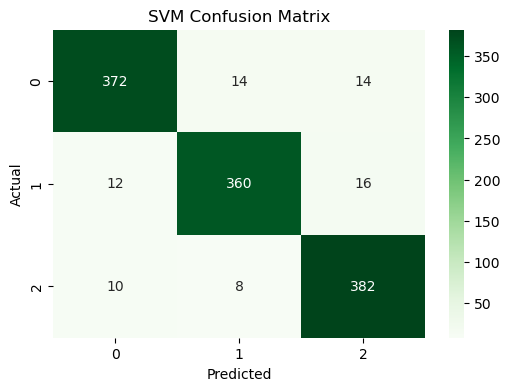

In [20]:
# Naive Bayes Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues')
plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens')
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Conclusion

In this project, machine learning models were developed to classify emotions in text samples.

The dataset was preprocessed using lowercase conversion, text cleaning, tokenization, and stopword removal. TF-IDF vectorization was used to convert text into numerical features.

Two machine learning algorithms, Multinomial Naive Bayes and Linear Support Vector Machine (SVM), were trained and evaluated.

The Naive Bayes model achieved an accuracy of 89.06%, while the SVM model achieved an accuracy of 93.77%.

Based on the evaluation results, SVM performed better than Naive Bayes for emotion classification.

Therefore, Linear SVM was selected as the best-performing model for this project.